# 03 — PSR, DSR and MinTRL in practice

Bailey & López de Prado's corrections turn a bare Sharpe ratio into a *probability*:

- **PSR** — P(true SR > benchmark), given sample length and the first four moments;
- **MinTRL** — the sample length at which that probability reaches a target confidence;
- **DSR** — PSR against the best SR expected by chance across all the trials you ran.

We exercise all three on simulated tracks where the truth is known.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from sharpe_illusion import simulation as sim
from sharpe_illusion import metrics, drawdown

PPY = sim.TRADING_DAYS_PER_YEAR
rng = np.random.default_rng(20260702)

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
    "grid.color": "#e1e0d9", "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, AQUA, RED, MUTED = "#2a78d6", "#1baf7a", "#e34948", "#898781"


## 1. PSR on a clean Gaussian track

Two years of daily data with a true SR of 1.0.

In [2]:
n = PPY * 2
r = sim.simulate_returns(1.0, n, 1, rng=rng)[0]
sr_pp = metrics.sharpe_ratio(r)
sr_ann = metrics.sharpe_ratio(r, periods_per_year=PPY)
psr = metrics.probabilistic_sharpe_ratio(sr_pp, n)
mintrl_yrs = metrics.minimum_track_record_length(sr_pp, confidence=0.95) / PPY

print(f"realized SR (annualized):  {sr_ann:.2f}")
print(f"PSR  P(true SR > 0):       {psr:.1%}")
print(f"MinTRL at 95%:             {mintrl_yrs:.1f} years "
      f"(we have {n / PPY:.0f})")

realized SR (annualized):  1.53
PSR  P(true SR > 0):       98.5%
MinTRL at 95%:             1.2 years (we have 2)


## 2. The short-vol trap: same Sharpe, worse PSR

Build a "sell insurance" return stream — steady small gains, rare large losses — and
measure its skewness and kurtosis. Then hold everything else fixed (same realized SR,
same track length) and ask the PSR the same question with Gaussian moments vs with the
short-vol moments. Only the *shape* of the distribution changes.

In [3]:
# a typical short-vol return profile: daily premium + rare crashes
n_sample = PPY * 40   # long sample, just to measure the moments cleanly
p_crash, crash_size = 0.01, 5.0
crashes = rng.random(n_sample) < p_crash
r_shortvol = 0.0944 + 0.5 * rng.normal(size=n_sample) - crash_size * crashes
g3 = stats.skew(r_shortvol)
g4 = stats.kurtosis(r_shortvol, fisher=False)
print(f"short-vol moments: skew = {g3:.2f}, kurtosis = {g4:.1f}  "
      f"(Gaussian: 0, 3)\n")

# same realized SR, same n — only the moments differ
n = PPY * 2
print(f"{'SR (ann.)':>10} | {'PSR, Gaussian moments':>22} | {'PSR, short-vol moments':>23}")
print("-" * 62)
for sr_ann in [0.5, 1.0, 1.5]:
    sr_pp = sr_ann / np.sqrt(PPY)
    psr_gauss = metrics.probabilistic_sharpe_ratio(sr_pp, n)
    psr_sv = metrics.probabilistic_sharpe_ratio(sr_pp, n, skew=g3, kurtosis=g4)
    print(f"{sr_ann:>10.1f} | {psr_gauss:>21.1%} | {psr_sv:>22.1%}")

short-vol moments: skew = -3.57, kurtosis = 27.0  (Gaussian: 0, 3)

 SR (ann.) |  PSR, Gaussian moments |  PSR, short-vol moments
--------------------------------------------------------------
       0.5 |                 76.0% |                  74.8%
       1.0 |                 92.1% |                  89.7%
       1.5 |                 98.3% |                  96.4%


Same headline Sharpe, same two years of data — but the four-moment PSR marks the
short-vol profile down at every level. The mechanism: negative skew and fat tails
inflate the variance of the SR estimator, so the same point estimate carries less
evidence. This is López de Prado's point that non-normality is not a footnote — and
the strategies it penalizes most (steady gains, rare disasters) are exactly the ones
whose raw Sharpe flatters them most.

## 3. Multiple testing: the Deflated Sharpe Ratio

A researcher backtests `N` configurations of a worthless strategy and reports the best.
The PSR of the winner looks great; the DSR — which benchmarks against the expected
maximum SR across `N` trials — is not fooled.

In [4]:
n = PPY * 2
n_trials = 200

# 200 zero-edge backtests; select the best
r_all = sim.simulate_returns(0.0, n, n_trials, rng=rng)
srs_pp = np.array([metrics.sharpe_ratio(r_all[i]) for i in range(n_trials)])
best = int(np.argmax(srs_pp))
sr_best = srs_pp[best]

psr = metrics.probabilistic_sharpe_ratio(sr_best, n)
dsr = metrics.deflated_sharpe_ratio(
    sr_best, n, n_trials=n_trials, sr_variance_across_trials=srs_pp.var())
e_max = metrics.expected_max_sharpe(n_trials, srs_pp.var())

print(f"best-of-{n_trials} realized SR (annualized): "
      f"{sr_best * np.sqrt(PPY):.2f}   <- pure luck, true SR = 0")
print(f"PSR of the winner (naive, benchmark 0):    {psr:.1%}  <- looks 'significant'")
print(f"expected max SR from luck alone (ann.):    {e_max * np.sqrt(PPY):.2f}")
print(f"DSR of the winner:                         {dsr:.1%}  <- correctly unimpressed")

best-of-200 realized SR (annualized): 1.76   <- pure luck, true SR = 0
PSR of the winner (naive, benchmark 0):    99.3%  <- looks 'significant'
expected max SR from luck alone (ann.):    1.91
DSR of the winner:                         41.7%  <- correctly unimpressed


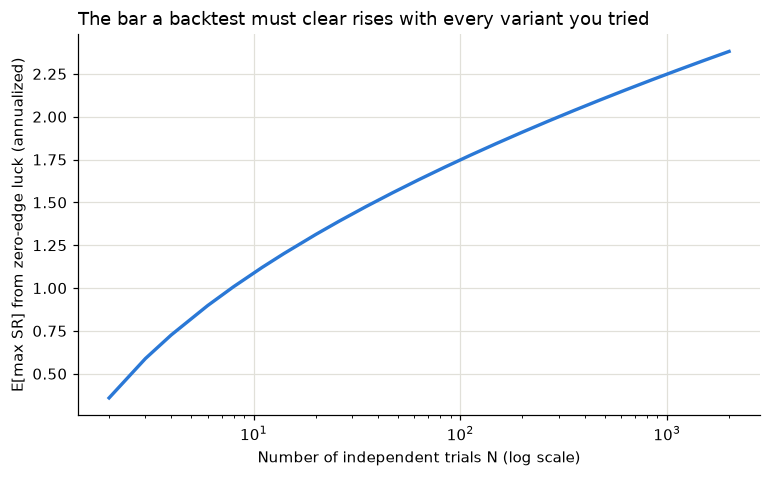

In [5]:
# How the luck-benchmark grows with the number of trials
trials_grid = np.unique(np.geomspace(2, 2000, 25).astype(int))
bench = [metrics.expected_max_sharpe(k, srs_pp.var()) * np.sqrt(PPY)
         for k in trials_grid]
fig, ax = plt.subplots()
ax.plot(trials_grid, bench, color=BLUE, lw=2.2)
ax.set_xscale("log")
ax.set_xlabel("Number of independent trials N (log scale)")
ax.set_ylabel("E[max SR] from zero-edge luck (annualized)")
ax.set_title("The bar a backtest must clear rises with every variant you tried",
             loc="left")
plt.show()

**Takeaways.**

1. A Sharpe ratio without `n`, skew, kurtosis and the trial count is not evidence.
2. PSR turns the point estimate into the probability you actually care about.
3. DSR raises the benchmark with every configuration you searched — with a few hundred
   trials, even an annualized SR of ~2 can be pure selection.

The full statistical background and references: [`docs/literature-overview.md`](../docs/literature-overview.md).